In [1]:
import numpy as np
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from accuracy_bounds.classificationproblems.utils import wavelet_array_features
from accuracy_bounds.classificationproblems.feasible_sets import feasible_sets_classification_nn
from accuracy_bounds.classificationproblems.kersize_compute import compute_kernel_size_one_hot

---
## Load the data

In [2]:
# number of subprocesses to use for data loading
num_workers = 0

# how many samples per batch to load
batch_size = 20

# percentage of training set to use as validation
valid_size = 0.2

# convert data to a normalized torch.FloatTensor
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2023, 0.1994, 0.2010)
    ),
])

# choose the training and test datasets
train_data = datasets.CIFAR10(
    "data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.CIFAR10(
    "data",
    train=False,
    download=True,
    transform=transform
)

# specify the image classes
classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

100%|██████████| 170M/170M [1:03:54<00:00, 44.5kB/s] 


## Average kernel size for one Mickey Mouse image to labels of CIFAR10

In [3]:
from collections import Counter

counts = Counter(test_data.targets)

M = len(test_data.targets)

same_pairs = sum(n * (n - 1) // 2 for n in counts.values())
total_pairs = M * (M - 1) // 2
diff_pairs = total_pairs - same_pairs

average_kersize = 2 * diff_pairs / total_pairs / 2

print(M)
print(counts)
print("Upper accuracy bound:", 1 - 0.5 * average_kersize)

10000
Counter({3: 1000, 8: 1000, 0: 1000, 6: 1000, 1: 1000, 9: 1000, 5: 1000, 7: 1000, 4: 1000, 2: 1000})
Upper accuracy bound: 0.54995499549955


## Average kernel size on training set

In [4]:
train_images = []
train_labels = []

for img, label in train_data:
    train_images.append(img.numpy())   # (3,32,32)
    train_labels.append(label)

train_images = np.stack(train_images)
train_labels = np.array(train_labels)

print(train_images.shape)   # (50000,3,32,32)
print(train_labels.shape)   # (50000,)

(50000, 3, 32, 32)
(50000,)


### Get wavelet features on training set

In [5]:
train_features = wavelet_array_features(train_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [6]:
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(train_features, train_labels, N_max=200,qx=0.05)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)

In [7]:
print("average_kersize on train set: ", average_kersize)

average_kersize on train set:  0.14391256029463206


### Ablation on quantiles and maximum number of nearest neighbors

In [8]:
average_kersize_list = []
tau_x_list = []
N_k_stats_list = []
N_max = 200
qx=0.05

#for qx in [0.01,0.02,0.03,0.05,0.06, 0.08, 0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
#for qx in [0.08]:
for N_max in [200]: #[10,20,30,40,50,100,200,300,450]:

    feas = feasible_sets_classification_nn(train_features, train_labels, N_max=N_max,qx=qx)
    tau_x= feas["tau_x"]
    feasible_sets= feas["feasible_sets"]
    D_prime = feas["D_prime"]
    distances = feas["distances"]
    indices = feas["indices"]

    average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
    average_kersize_list.append(average_kersize)
    tau_x_list.append(tau_x)
    N_k_stats_list.append(Nk_stats)

print("Average kernel sizes on train set:", average_kersize_list)
print("Tau x values on train set:", tau_x_list)
print("N k statistics on train set:", N_k_stats_list)

Average kernel sizes on train set: [np.float64(0.14391256029463206)]
Tau x values on train set: [27.4023157119751]
N k statistics on train set: [(1, 1.3044, 1.0, 188)]


## Average kernel size on test set

In [9]:
test_images = []
test_labels = []

for img, label in test_data:
    test_images.append(img.numpy())   # (3,32,32)
    test_labels.append(label)

test_images = np.stack(test_images)
test_labels = np.array(test_labels)

print(test_images.shape)   # (10000,3,32,32)
print(test_labels.shape)   # (10000,)

(10000, 3, 32, 32)
(10000,)


### Get wavelet features on test set

In [10]:
test_features = wavelet_array_features(test_images, wavelet="haar")

### Compute average kernel size from feasible sets with nearest neighbors and wavelet features induced pseudometric

In [11]:
feas = feasible_sets_classification_nn(test_features, test_labels, N_max=200,qx=0.05)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
print("Average kernel size on test set: ", average_kersize)

Average kernel size on test set:  0.16243666545803492


### Best accuracy on contructed test dataset

In [12]:
def compute_accuracy_star(feasible_sets):
    """Compute Acc_* for a collection of feasible sets."""
    return sum(
        max(np.bincount(Y.astype(int)))
        for Y in feasible_sets if len(Y)
    ) / sum(len(Y) for Y in feasible_sets)


Acc = compute_accuracy_star(feasible_sets)
print("Best accuracy on constructed test dataset", Acc)

Best accuracy on constructed test dataset 0.8842713955281418


### Ablation on quantiles and maximum number of nearest neighbors

In [13]:
average_kersize_list = []
tau_x_list = []
N_k_stats_list = []
N_max = 200
qx=0.05

#for qx in [0.01,0.02,0.03,0.05,0.06, 0.08, 0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
#for qx in [0.08]:
for N_max in [200]: #[10,20,30,40,50,100,200,300,450]:

    feas = feasible_sets_classification_nn(test_features, test_labels, N_max=N_max,qx=qx)
    tau_x= feas["tau_x"]
    feasible_sets= feas["feasible_sets"]
    D_prime = feas["D_prime"]
    distances = feas["distances"]
    indices = feas["indices"]

    average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
    average_kersize_list.append(average_kersize)
    tau_x_list.append(tau_x)
    N_k_stats_list.append(Nk_stats)

print("Average kernel sizes on test set:", average_kersize_list)
print("Tau x values on test set:", tau_x_list)
print("N k statistics on test set:", N_k_stats_list)

Average kernel sizes on test set: [np.float64(0.16243666545803492)]
Tau x values on test set: [30.80175609588623]
N k statistics on test set: [(1, 1.297, 1.0, 79)]


## Visualize Feasible Sets

In [14]:
# generate feasible sets on test set for visualization
# N_max is maximum number of neighbors to consider for feasible sets, qx is the quantile for distance threshold
feas = feasible_sets_classification_nn(test_features, test_labels, test_images, N_max=200,qx=0.05, ext_d = True)
tau_x= feas["tau_x"]
feasible_sets= feas["feasible_sets"]
D_prime = feas["D_prime"]
distances = feas["distances"]
indices = feas["indices"]

tau_x: 24.67328996658325


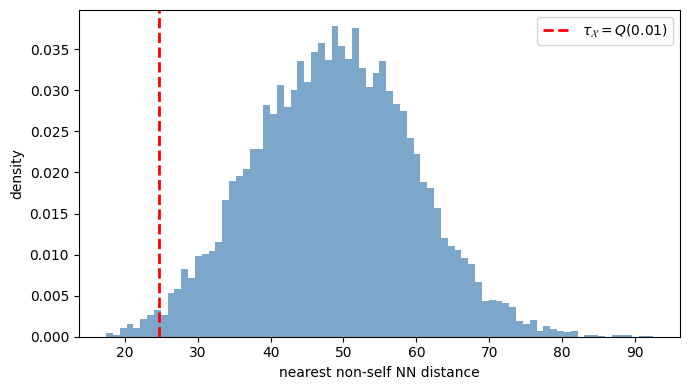

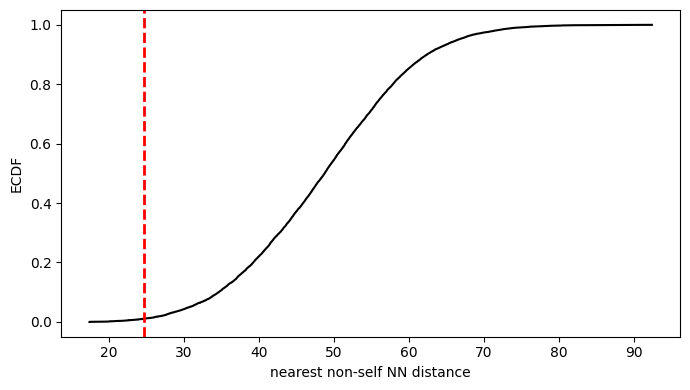

In [15]:


nearest_dist = distances[:, 1]  # nearest non-self distance
tau_x = np.quantile(nearest_dist, 0.01)

print("tau_x:", tau_x)

# --- histogram (log-scale on y often helps) ---
plt.figure(figsize=(7,4))
plt.hist(nearest_dist, bins=80, density=True, alpha=0.7, color="steelblue")
plt.axvline(tau_x, color="red", linestyle="--", linewidth=2,
            label=fr"$\tau_\mathcal{{X}} = Q({0.01})$")
plt.xlabel("nearest non-self NN distance")
plt.ylabel("density")
plt.legend()
plt.tight_layout()
plt.show()

# --- ECDF plot (often more informative than histograms) ---
x = np.sort(nearest_dist)
y = np.arange(1, len(x)+1) / len(x)

plt.figure(figsize=(7,4))
plt.plot(x, y, color="black")
plt.axvline(tau_x, color="red", linestyle="--", linewidth=2)
plt.xlabel("nearest non-self NN distance")
plt.ylabel("ECDF")
plt.tight_layout()
plt.show()


In [16]:


_MEAN = np.array([0.4914, 0.4822, 0.4465], dtype=np.float32)[:, None, None]
_STD  = np.array([0.2023, 0.1994, 0.2010], dtype=np.float32)[:, None, None]

def unnormalize(img):
    """
    Undo CIFAR-10 normalization.

    Parameters
    ----------
    img : ndarray, shape (3, H, W)

    Returns
    -------
    ndarray, shape (3, H, W), values in [0,1]
    """
    img = img.copy()
    img = img * _STD + _MEAN
    return np.clip(img, 0.0, 1.0)

def show_neighbor_pairs(test_images, indices, distances, tau_x, num_pairs=5, labels=None):
    """
    Visualize pairs of images that are nearest neighbors within tau_x.
    If `labels` is provided (a list/array of class names or label indices,
    one per image in test_images), it's included in each subplot title.
    """
    pairs = []
    # loop over anchor images
    for i in range(len(test_images)):
        for idx, dist in zip(indices[i], distances[i]):
            if dist <= tau_x and i != idx:
                pairs.append((i, idx, dist))
    # plot pairs
    fig, axes = plt.subplots(num_pairs, 2, figsize=(6, 3 * num_pairs))
    if num_pairs == 1:
        axes = np.expand_dims(axes, 0)
    np.random.shuffle(pairs)
    pairs = pairs[:min(len(pairs), num_pairs)]
    for row, (i, j, dist) in enumerate(pairs):
        img1 = np.transpose(unnormalize(test_images[i]), (1, 2, 0))
        img2 = np.transpose(unnormalize(test_images[j]), (1, 2, 0))
        title1 = f"Anchor i={i}"
        title2 = f"Neighbor j={j}, d={dist:.3f}"
        if labels is not None:
            title1 += f"\nlabel={labels[i]}"
            title2 += f"\nlabel={labels[j]}"
        axes[row, 0].imshow(img1)
        axes[row, 0].set_title(title1)
        axes[row, 0].axis("off")
        axes[row, 1].imshow(img2)
        axes[row, 1].set_title(title2)
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()


def show_class_neighbor_grid(test_images, indices, distances, labels, num_neighbors=10, classes=None):
    """
    Build a grid with one row per class. For each class, pick a random
    anchor image from that class and plot its `num_neighbors` closest
    neighbors (columns) based on precomputed `indices`/`distances`.

    Parameters
    ----------
    test_images : array-like, shape (N, 3, H, W)
    indices : array-like, shape (N, k) - neighbor indices per image (e.g. from a NN search)
    distances : array-like, shape (N, k) - corresponding distances
    labels : array-like, shape (N,) - class label (int or str) per image, used to
             pick one random anchor per class
    num_neighbors : int, number of closest neighbors to show per row (default 10)
    classes : optional list mapping label index -> class name, used for row titles
    """
    num_neighbors += 1 # first image should be original 
    labels = np.asarray(labels)
    unique_classes = np.unique(labels)
    num_classes = len(unique_classes)

    fig, axes = plt.subplots(num_classes, num_neighbors,
                              figsize=(2 * num_neighbors, 2 * num_classes))
    if num_classes == 1:
        axes = np.expand_dims(axes, 0)
    if num_neighbors == 1:
        axes = np.expand_dims(axes, 1)

    for row, cls in enumerate(unique_classes):
        # pick a random anchor belonging to this class
        cls_pool = np.where(labels == cls)[0]
        anchor = np.random.choice(cls_pool)

        # get neighbors sorted by distance, excluding the anchor itself
        neighbor_idx = np.array(indices[anchor])
        neighbor_dist = np.array(distances[anchor])
        order = np.argsort(neighbor_dist)
        neighbor_idx = neighbor_idx[order]
        neighbor_dist = neighbor_dist[order]

        neighbor_idx = neighbor_idx[:num_neighbors]
        neighbor_dist = neighbor_dist[:num_neighbors]

        class_name = classes[cls] if classes is not None else cls

        for col in range(num_neighbors):
            ax = axes[row, col]
            if col < len(neighbor_idx):
                j = neighbor_idx[col]
                dist = neighbor_dist[col]
                img = np.transpose(unnormalize(test_images[j]), (1, 2, 0))
                ax.imshow(img)
                title = f"d={dist:.3f}"
                if col == 0:
                    title = f"class={class_name}\nanchor={anchor}\n" + title
                ax.set_title(title, fontsize=8)
            ax.axis("off")

    plt.tight_layout()
    plt.show()

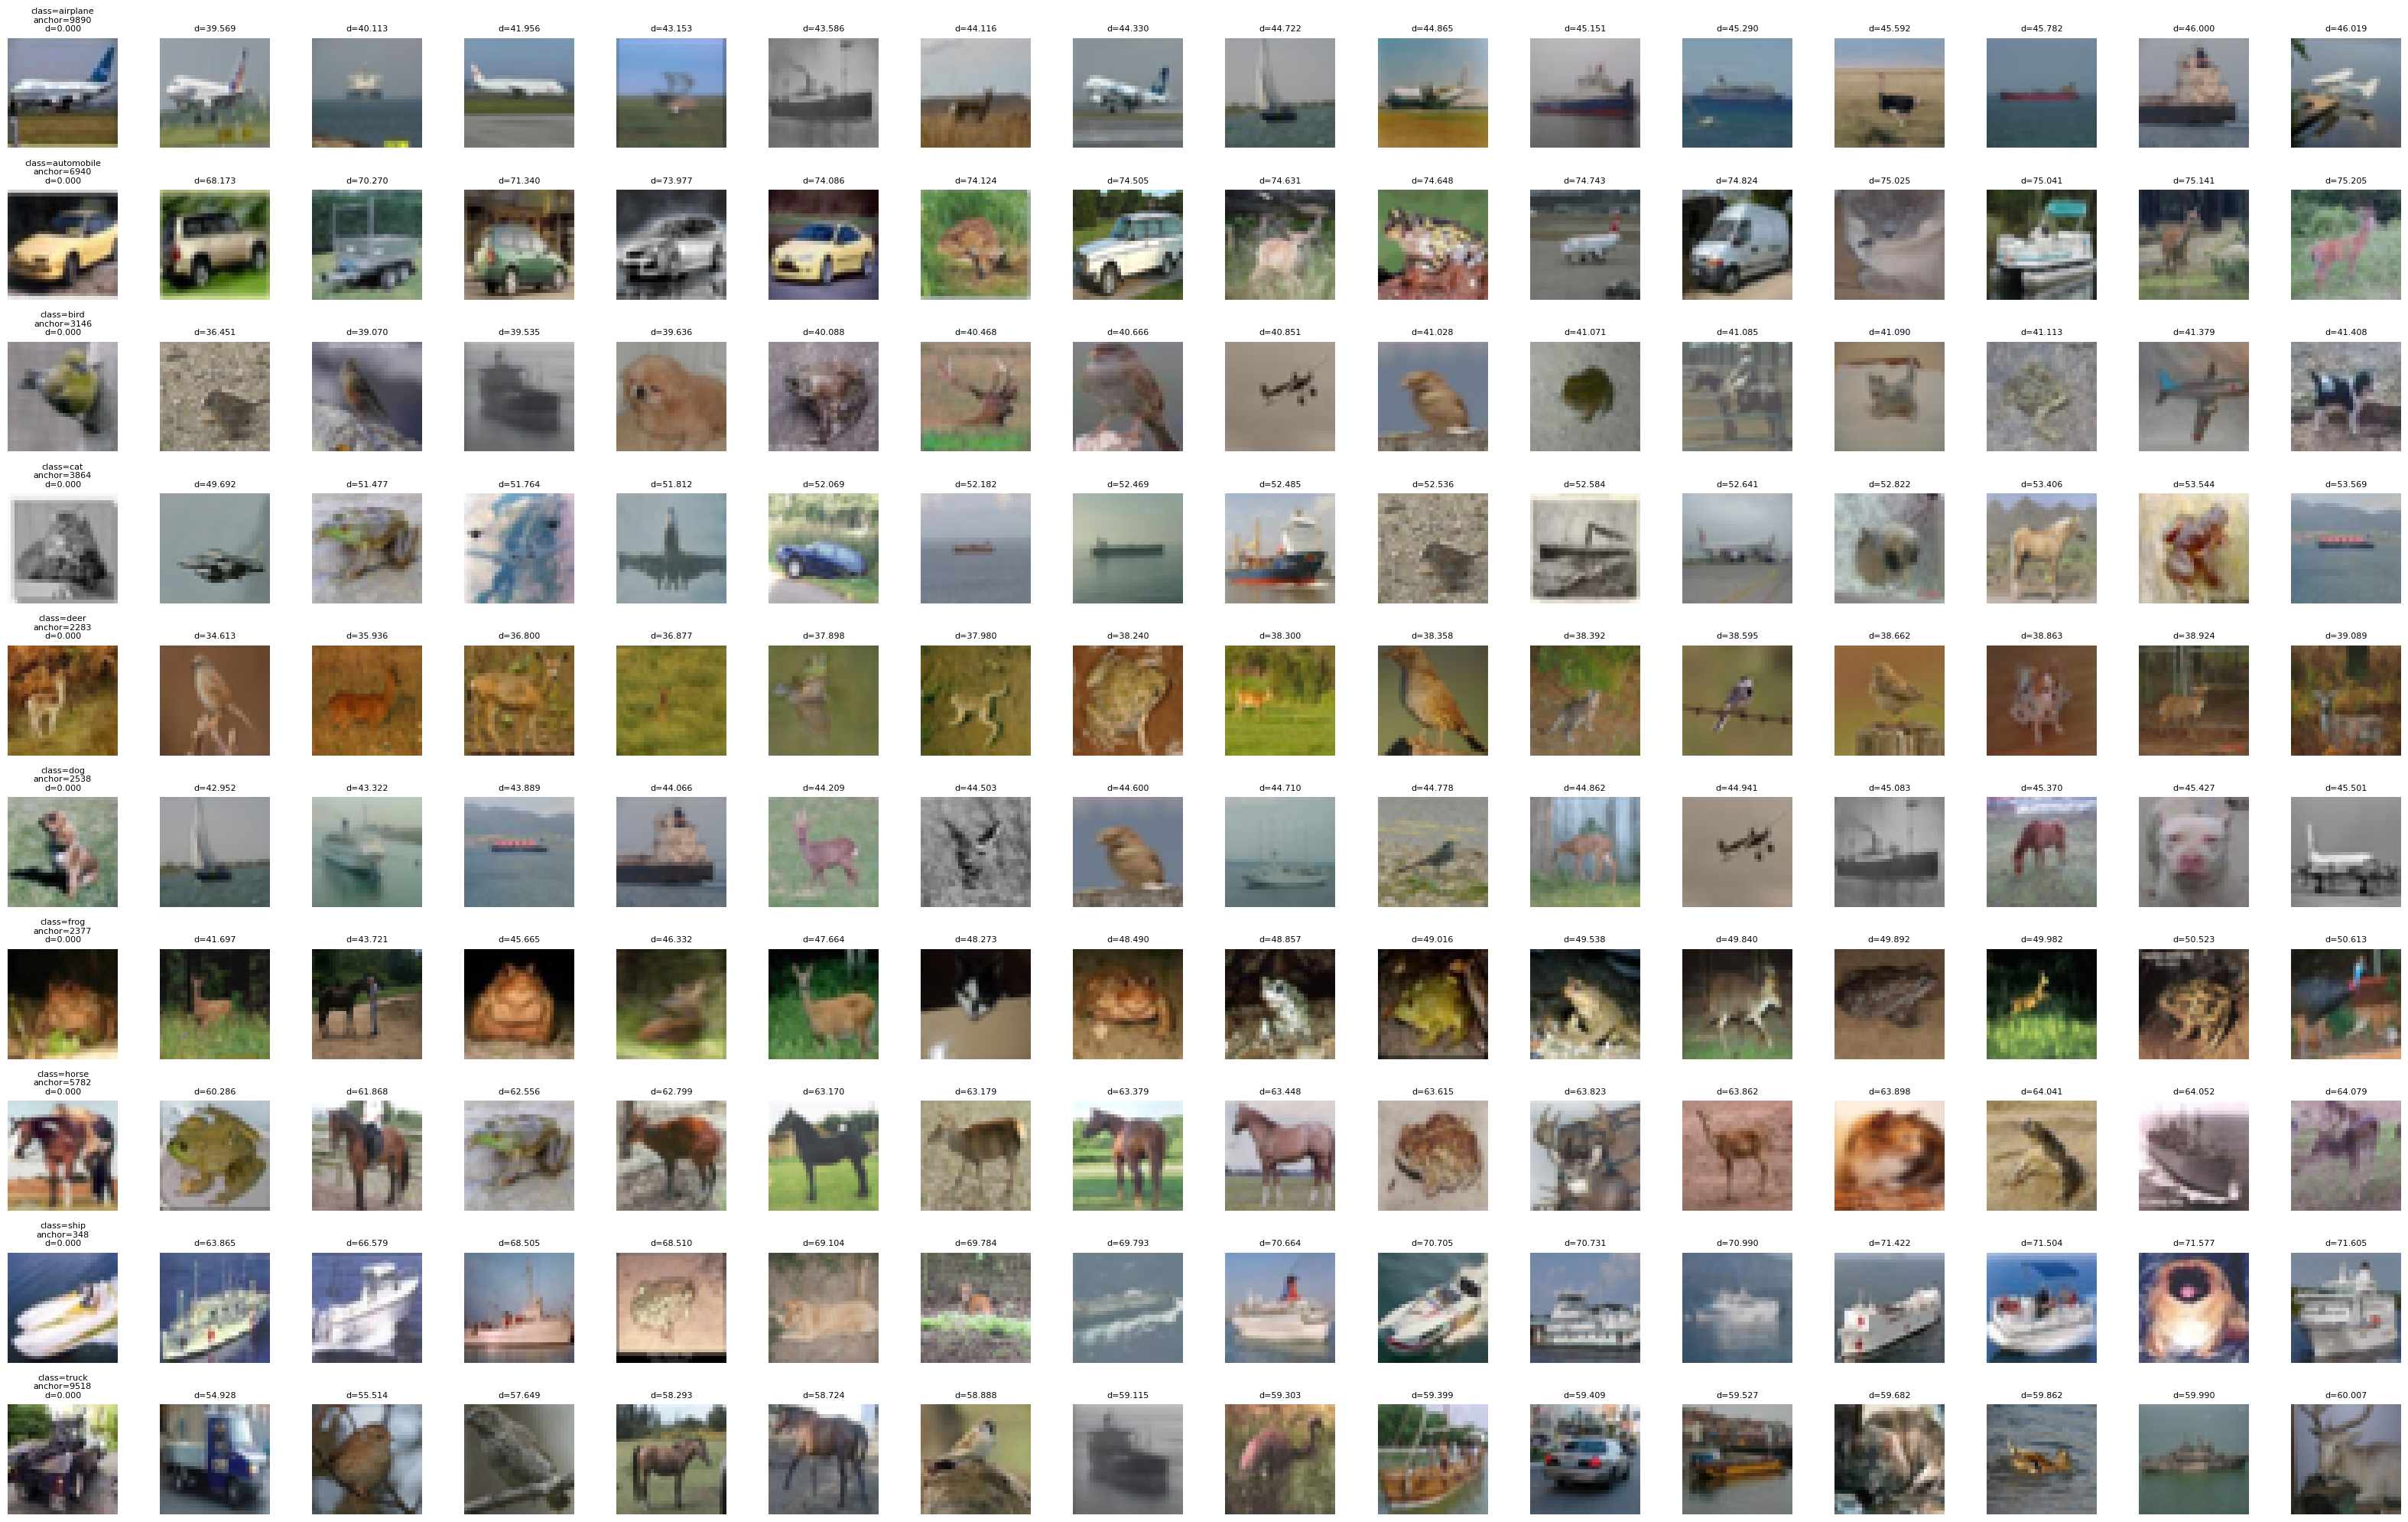

In [17]:
show_class_neighbor_grid(test_images, 
                         indices, 
                         distances, 
                         labels=test_labels, 
                         num_neighbors=15, 
                         classes=classes)

## Plot Wavelet Decomposition


In [18]:
import pywt
import numpy as np

def plot_wavelet_decomposition(img, wavelet='haar'):
    """
    Plot CIFAR-10 RGB image + wavelet decomposition per channel.

    img: (3, 32, 32)
    """

    if hasattr(img, "numpy"):
        img = img.numpy()

    channel_names = ['Red', 'Green', 'Blue']

    fig, axes = plt.subplots(3, 5, figsize=(15, 8))

    for c in range(3):

        # --- RGB image ---
        rgb = np.transpose(img, (1, 2, 0))

        axes[c, 0].imshow(rgb)
        axes[c, 0].set_title(f"Original RGB ({channel_names[c]} row)")

        # Add a clear row label on the left side
        axes[c, 0].set_ylabel(
            f"{channel_names[c]} channel",
            rotation=90,
            labelpad=10,
            fontsize=12
        )

        # --- Wavelet transform ---
        LL, (LH, HL, HH) = pywt.dwt2(img[c], wavelet)

        axes[c, 1].imshow(LL, cmap='gray')
        axes[c, 1].set_title(f'LL ({channel_names[c]})')

        axes[c, 2].imshow(LH, cmap='gray')
        axes[c, 2].set_title(f'LH ({channel_names[c]})')

        axes[c, 3].imshow(HL, cmap='gray')
        axes[c, 3].set_title(f'HL ({channel_names[c]})')

        axes[c, 4].imshow(HH, cmap='gray')
        axes[c, 4].set_title(f'HH ({channel_names[c]})')

        for j in range(5):
            axes[c, j].axis('off')

    plt.tight_layout()
    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8702078..2.01008].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8702078..2.01008].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8702078..2.01008].


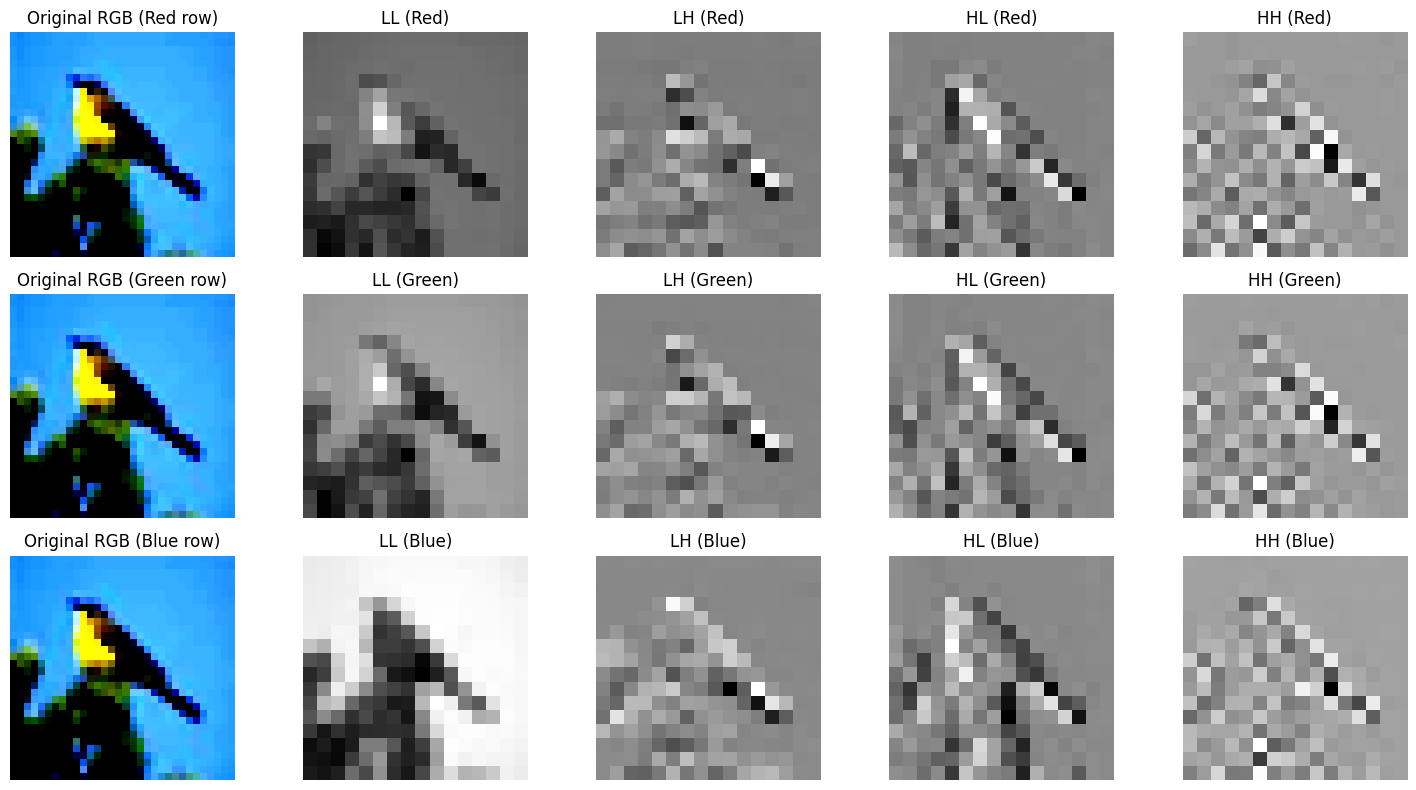

In [19]:
plot_wavelet_decomposition(train_images[1800])

## Test on models on test data and enlarged test data

In [20]:
import torch

from models.resnet import cifar10_resnet56
from models.shufflenetv2 import cifar10_shufflenetv2_x0_5

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [21]:
# Paths to weights
resnet_path = "models/cifar10_resnet56.pt"

shuffle_path = "models/cifar10_shufflenetv2_x0_5.pt"

# Instantiate models
phi_1st = cifar10_resnet56()
phi_2nd = cifar10_shufflenetv2_x0_5()

# Load checkpoints
phi_1st.load_state_dict(torch.load(resnet_path, map_location=device))
phi_2nd.load_state_dict(torch.load(shuffle_path, map_location=device))

phi_1st.to(device).eval()
phi_2nd.to(device).eval()

ShuffleNetV2(
  (conv1): Sequential(
    (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (stage2): Sequential(
    (0): InvertedResidual(
      (branch1): Sequential(
        (0): Conv2d(24, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=24, bias=False)
        (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (3): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (4): ReLU(inplace=True)
      )
      (branch2): Sequential(
        (0): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)


### Evaluate models

In [22]:
@torch.no_grad()
def evaluate_accuracy(model, loader, device):
    model.eval()

    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # predicted class
        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / total

In [23]:
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

resnet_acc = evaluate_accuracy(phi_1st, test_loader, device)
shuffle_acc = evaluate_accuracy(phi_2nd, test_loader, device)

print(f"ResNet56 test accuracy:     {resnet_acc:.2f}%")
print(f"ShuffleNetV2 test accuracy: {shuffle_acc:.2f}%")

ResNet56 test accuracy:     91.20%
ShuffleNetV2 test accuracy: 83.19%


In [24]:
from torch.utils.data import TensorDataset

D_prime_features = np.stack(
    [x[0] for x in D_prime]
)

D_prime_labels = np.array(
    [x[1] for x in D_prime]
)

D_prime_features_tensor = torch.tensor(
    D_prime_features,
    dtype=torch.float32
)

D_prime_labels_tensor = torch.tensor(
    D_prime_labels,
    dtype=torch.long
)

D_prime_dataset = TensorDataset(
    D_prime_features_tensor,
    D_prime_labels_tensor
)

d_prime_loader = DataLoader(
    D_prime_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

resnet_acc = evaluate_accuracy(phi_1st, d_prime_loader, device)
shuffle_acc = evaluate_accuracy(phi_2nd, d_prime_loader, device)

print(f"ResNet56 test accuracy:     {resnet_acc:.2f}%")
print(f"ShuffleNetV2 test accuracy: {shuffle_acc:.2f}%")

ResNet56 test accuracy:     79.31%
ShuffleNetV2 test accuracy: 73.24%


In [25]:
print(len(D_prime_dataset))

12970


# Average Kernel Size for Random Labels

In [26]:
from accuracy_bounds.classificationproblems.feasible_sets import feasible_sets_classification_nn_tauy

In [27]:

# Generate random labels: 0–9
random_labels_train = np.random.randint(0, 10, size=len(train_images))

print(train_images.shape)     # (50000, 3, 32, 32)
print(random_labels_train.shape)    # (50000,)


(50000, 3, 32, 32)
(50000,)


## Compute average kernel size on train set with random labels

In [28]:
average_kersize_list = []
tau_x_list = []
N_k_stats_list = []
N_max = 200
qx=0.1

#for qx in [0.01,0.02,0.03,0.05,0.06, 0.08, 0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
#for qx in [0.08]:
for N_max in [600]: #[10,20,30,40,50,100,200,300,450]:

    feas = feasible_sets_classification_nn_tauy(train_features, random_labels_train, N_max=N_max,qx=qx)
    tau_x= feas["tau_x"]
    feasible_sets= feas["feasible_sets"]
    D_prime = feas["D_prime"]
    distances = feas["distances"]
    indices = feas["indices"]

    average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
    average_kersize_list.append(average_kersize)
    tau_x_list.append(tau_x)
    N_k_stats_list.append(Nk_stats)

print("Average kernel sizes on train set:", average_kersize_list)
print("Tau x values on train set:", tau_x_list)
print("N k statistics on train set:", N_k_stats_list)

Average kernel sizes on train set: [np.float64(0.935083210462791)]
Tau x values on train set: [31.467905235290527]
N k statistics on train set: [(3, 8.30892, 3.0, 1611)]


In [29]:
# Generate random labels: 0–9
random_labels_test = np.random.randint(0, 10, size=len(test_images))

print(test_images.shape)     # (10000, 3, 32, 32)
print(random_labels_test.shape)    # (10000,)


(10000, 3, 32, 32)
(10000,)


## Compute average kernel size on test set with random labels

In [30]:
average_kersize_list = []
tau_x_list = []
N_k_stats_list = []
N_max = 200
qx=0.1

#for qx in [0.01,0.02,0.03,0.05,0.06, 0.08, 0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]:
#for qx in [0.08]:
for N_max in [600]: #[10,20,30,40,50,100,200,300,450]:

    feas = feasible_sets_classification_nn_tauy(test_features, random_labels_test, N_max=N_max,qx=qx)
    tau_x= feas["tau_x"]
    feasible_sets= feas["feasible_sets"]
    D_prime = feas["D_prime"]
    distances = feas["distances"]
    indices = feas["indices"]

    average_kersize, M_prime, Nk_stats = compute_kernel_size_one_hot(feasible_sets)
    average_kersize_list.append(average_kersize)
    tau_x_list.append(tau_x)
    N_k_stats_list.append(Nk_stats)

print("Average kernel sizes on test set:", average_kersize_list)
print("Tau x values on test set:", tau_x_list)
print("N k statistics on test set:", N_k_stats_list)

Average kernel sizes on test set: [np.float64(0.9433327807534124)]
Tau x values on test set: [34.681372833251956]
N k statistics on test set: [(3, 6.7902, 3.0, 507)]
